# Exploración de resultados — Práctica 2 (SARSA y Q-learning)

Cuaderno de inspección: carga los resultados guardados por `run_experiments.py` (no reentrena salvo la última celda) y reproduce las cifras clave del informe. Orden de uso: `validate_algorithms.py` → `run_experiments.py` → `analyze_results.py` → este cuaderno.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import *
from loaders import load_runs, stack, first_stable
P = make_env().unwrapped.P
QS = q_star(P); QE = soft_optimal_q(P, GAMMA, 0.2)[0]
REACH = reachable_states(P)
print('alcanzables:', REACH)
print('inalcanzables:', [s for s in range(20) if s not in REACH])
print('sin ruta al objetivo:', [s for s in range(20) if s not in goal_reachable(P)])

alcanzables: [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 18, 19]
inalcanzables: [2, 16, 17]
sin ruta al objetivo: [1, 15, 16, 18, 19]


## Referencias teóricas: $q_*$ y $q_arepsilon$ ($arepsilon=0.2$)

In [2]:
pd.DataFrame({'q*(↗)': QS[:20,0], 'q*(↘)': QS[:20,1], 'q_eps(↗)': QE[:20,0], 'q_eps(↘)': QE[:20,1]}).round(4)

,q*(↗),q*(↘),q_eps(↗),q_eps(↘)
0,-5.0000,0.9350,-5.0000,0.0543
1,-5.0000,-5.0000,-5.0000,-5.0000
2,-5.0000,3.5000,-5.0000,3.5000
3,3.5000,3.5000,3.5000,3.5000
4,-5.5000,-0.1585,-5.5000,-1.8146
5,-5.0000,2.1500,-5.0000,1.8572
6,2.1500,5.0000,2.1500,5.0000
7,5.0000,5.0000,5.0000,5.0000
8,0.9350,-5.0000,0.0543,-5.0000
9,-5.0000,0.9350,-5.0000,-0.4501


## Resumen de todas las configuraciones (una fila por configuración y algoritmo)

In [3]:
summ = pd.read_csv(RESULTS / 'summaries' / 'hyperparameter_summary.csv')
summ[['group','config','algo','alpha','epsilon','q_init','eval_final','policy_stable_ep','ret_500_10k','ret_10k_20k','q13_ur_tail_mean','q13_ur_tail_sd','max_err_qstar','s10_dr_500_10k']].round(3)

,group,config,algo,alpha,epsilon,q_init,eval_final,policy_stable_ep,ret_500_10k,ret_10k_20k,q13_ur_tail_mean,q13_ur_tail_sd,max_err_qstar,s10_dr_500_10k
0,base,base,sarsa,0.10,0.20,0.0,1.500,1508.5,-0.760,-0.763,1.302,0.576,2.195,0.062
1,base,base,q_learning,0.10,0.20,0.0,1.500,1454.0,-0.945,-0.746,2.150,0.000,0.042,0.671
2,alpha,alpha_0.01,sarsa,0.01,0.20,0.0,1.500,17187.0,-0.995,-0.748,1.329,0.165,2.205,0.552
3,alpha,alpha_0.01,q_learning,0.01,0.20,0.0,1.500,17602.5,-1.031,-0.949,2.150,0.000,3.236,0.700
4,alpha,alpha_0.05,sarsa,0.05,0.20,0.0,1.500,3436.5,-0.775,-0.739,1.286,0.406,1.854,0.104
5,alpha,alpha_0.05,q_learning,0.05,0.20,0.0,1.500,3368.0,-0.997,-0.972,2.150,0.000,1.966,0.900
6,alpha,alpha_0.5,sarsa,0.50,0.20,0.0,1.175,19178.5,-1.055,-0.916,1.195,1.591,2.839,0.220
7,alpha,alpha_0.5,q_learning,0.50,0.20,0.0,1.500,202.5,-0.761,-0.741,2.150,0.000,0.000,0.072
8,alpha,alpha_1.0,sarsa,1.00,0.20,0.0,-4.900,-1.0,-4.659,-4.618,-3.167,3.869,8.505,0.213
9,alpha,alpha_1.0,q_learning,1.00,0.20,0.0,1.500,75.5,-0.719,-0.722,2.150,0.000,0.000,0.000


## SARSA en $s_{13}$: media y desviación estacionarias frente a la predicción AR(1)

In [4]:
pd.read_csv(RESULTS / 'summaries' / 'alpha_s13.csv').round(3)

,alpha,sd_theory,sd_sarsa,mean_sarsa,drop_theory,q_ql,eval_sarsa,eval_ql,pol_sarsa_median,pol_ql_median
0,0.01,0.181,0.171,1.329,0.077,2.15,1.500,1.5,17187.0,17602.5
1,0.05,0.409,0.411,1.286,0.383,2.15,1.500,1.5,3436.5,3368.0
2,0.10,0.585,0.578,1.308,0.765,2.15,1.500,1.5,1597.5,1414.5
3,0.50,1.473,1.658,1.195,3.827,2.15,1.175,1.5,19274.0,202.5
4,1.00,2.552,4.117,-3.167,7.654,2.15,-4.900,1.5,inf,75.5


## Retorno de entrenamiento por fases (configuración basal, 20 semillas pareadas)

In [5]:
pd.read_csv(RESULTS / 'summaries' / 'returns_by_phase.csv').round(4)

,phase,sarsa,ql,diff,lo,hi,p,ql_s10_dr,sarsa_s10_dr,sarsa_wins
0,"[0,100)",-2.7770,-2.5895,-0.1875,-0.3090,-0.0715,0.0078,0.6480,0.6130,5
1,"[100,500)",-1.0530,-0.9885,-0.0645,-0.1505,0.0178,0.1571,0.7000,0.5974,6
2,"[500,10000)",-0.7600,-0.9447,0.1846,0.1204,0.2431,0.0001,0.6711,0.0625,15
3,"[10000,20000)",-0.7626,-0.7456,-0.0170,-0.0369,0.0043,0.1303,0.0131,0.0391,7


## Inspección libre: $Q(s,a)$ de cualquier par seguido en una ejecución
`q_track` guarda por episodio los estados (3, 6, 10, 11, 13, 14); `q_sub`, la tabla completa cada 10 episodios.

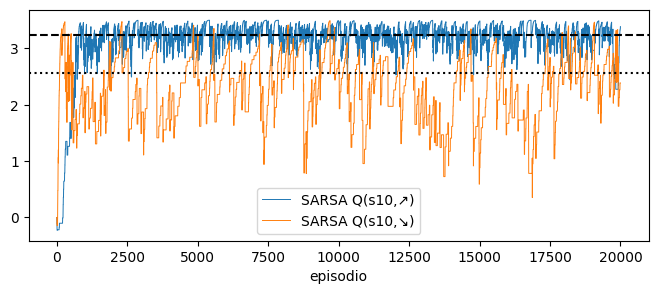

In [6]:
R = load_runs('base', 'base', 'sarsa')
track = list(R[0]['track'])
fig, ax = plt.subplots(figsize=(8, 3))
for s, a in [(10, 0), (10, 1)]:
    ax.plot(R[0]['q_track'][:, track.index(s), a], lw=0.7, label=f'SARSA Q(s{s},{"↗↘"[a]})')
ax.axhline(QE[10, 0], ls='--', c='k'); ax.axhline(QE[10, 1], ls=':', c='k')
ax.set_xlabel('episodio'); ax.legend(); plt.show()

## Reentrenar una configuración puntual (usa las funciones reales de `lab2/src`)

In [7]:
r = run_training('q_learning', 3000, alpha=0.1, epsilon=0.2, q_init=0.0, seed=0)
print('Q(s13,·) =', r['Q'][13], '| retorno greedy final por s_init =', r['eval_ret'][-1])

Q(s13,·) = [ 2.15       -5.49086026] | retorno greedy final por s_init = [2. 1. 2. 1.]
